# Module 8. Neural Networks and Deep Learning

## 8.1 - Project: Fashion Classification

### From tables (structured) to images (unstructured)

In all previous modules, we worked with tabular data (CSVs with rows and columns). Linear regression, logistic regression and tree-based models are all made for data like this.

This week the data is different. Instead of a table, we have images - pictures of clothes. Given a picture, we want to predict what kind of clothing it shows.

The project is multi-class classification. We build a model that tells whether an image belongs to one of 10 clothing categories.

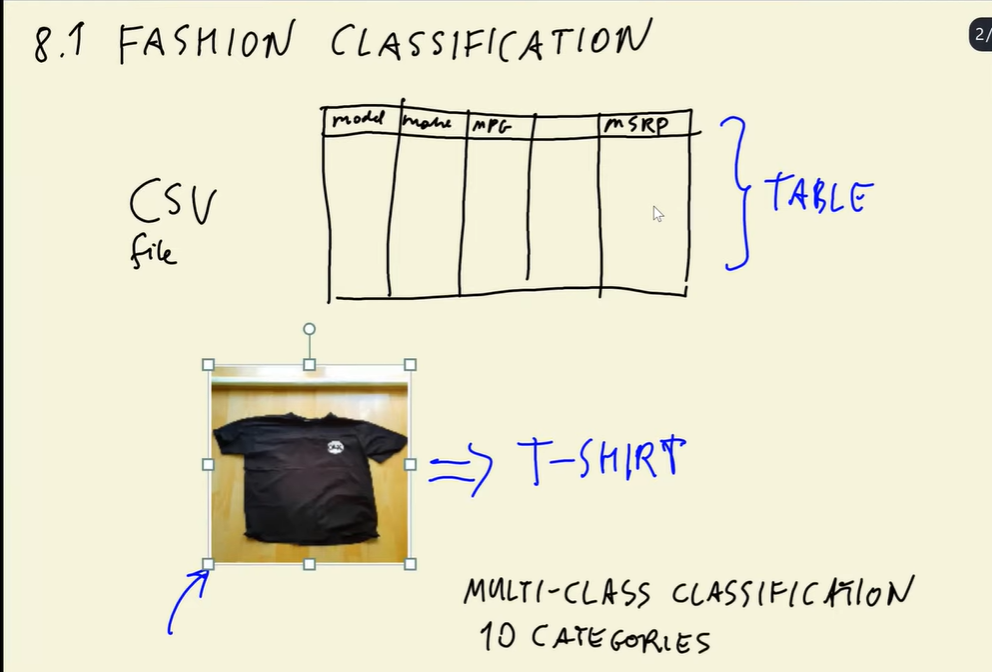

### Use case

An online marketplace website, the kind where people sell things. A user wants to sell a t-shirt, so they create a listing in the fashion category and upload a picture of it.

On the backend we have a fashion classification service. It takes the picture and replies with a suggested category - in this case "t-shirt". The user sees the suggestion, clicks publish, and the listing is done. Uploading a picture and clicking publish is much simpler than picking a category by hand, so this helps users create listings faster.

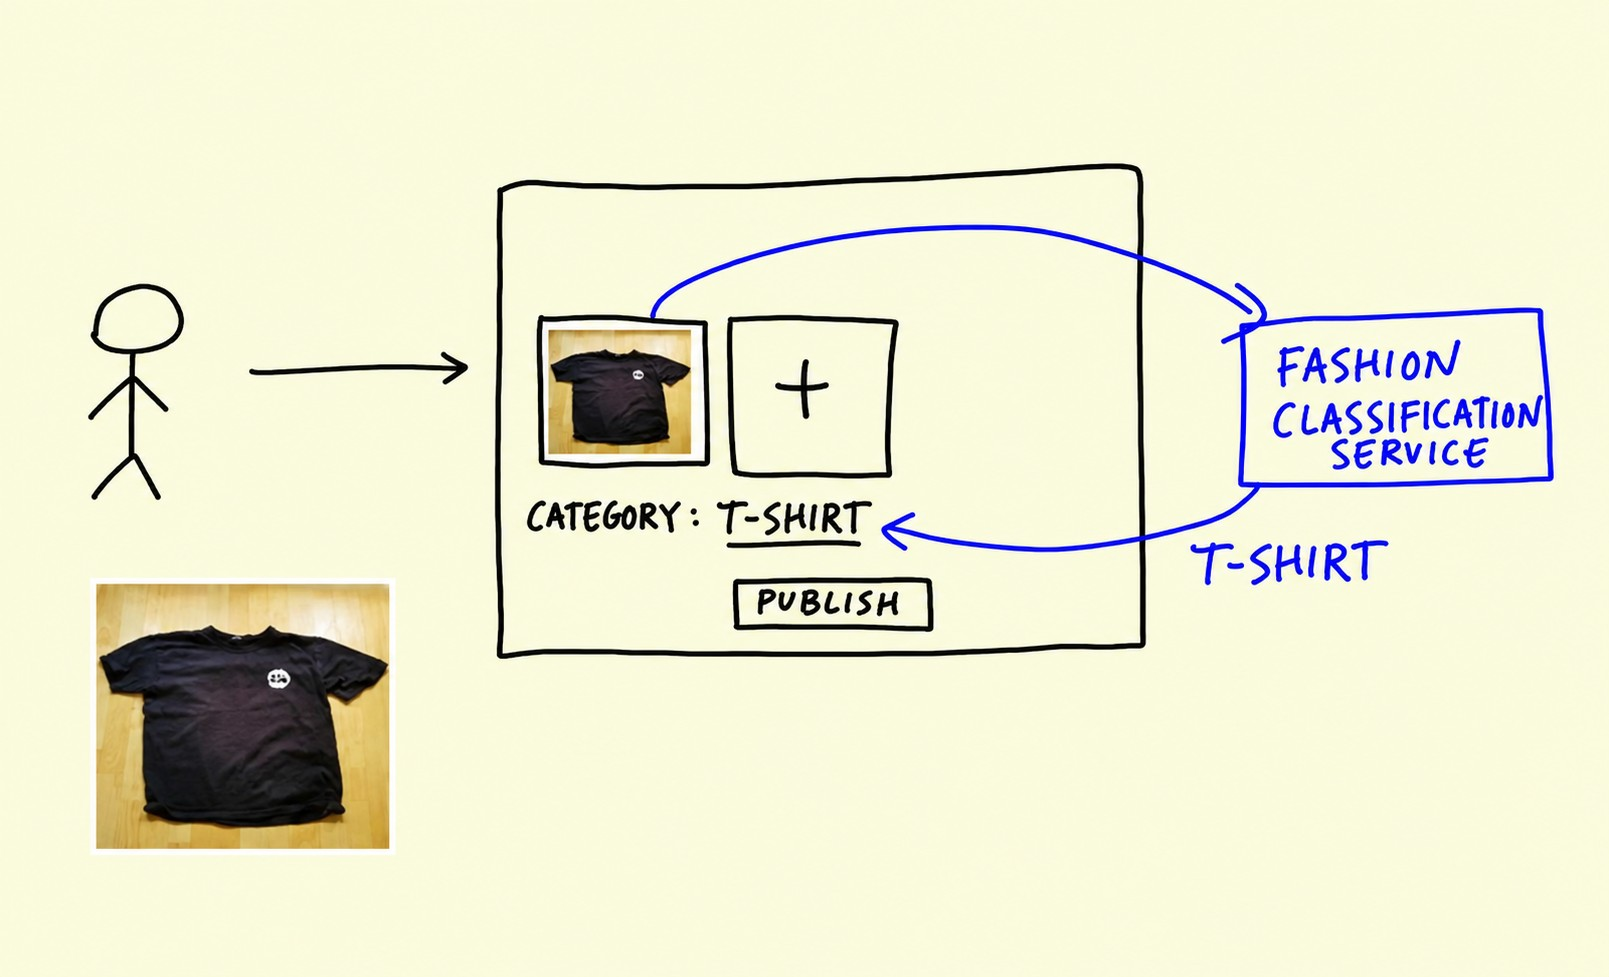

### Dataset

Clone this repo:
https://github.com/alexeygrigorev/clothing-dataset-small

## 8.2 - Tensorflow and Keras

### What is Tensorflow and Keras?

TensorFlow is a library from Google for doing deep learning. Its an end-to-end open source machine learning platform - it can do other things, but the main focus is deep learning. For us, TensorFlow is a library for training deep learning models.

Keras is a higher-level abstraction on top of TensorFlow. It makes it simpler to create, train and use neural networks. Keras lives inside TensorFlow. Keras used to be a separate library, but it got absorbed into TensorFlow. Since TensorFlow 2.0 it is a part of TensorFlow - so make sure you use TensorFlow 2.0 or above.

### Install TensorFlow + Keras (GPU)

```bash
uv add "tensorflow[and-cuda]"   # Keras is included
```

Check the GPU is detected:

```python
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))  # [] means CPU only
```


In [3]:
import numpy as np
import matplotlib.pyplot as plt

import ctypes, os, nvidia.cusolver
# TF 2.21 can't find cuSOLVER on its own, so load it first
ctypes.CDLL(os.path.join(nvidia.cusolver.__path__[0], 'lib', 'libcusolver.so.11'))

# hide TF info messages
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  

import tensorflow as tf

import tensorflow as tf
from tensorflow import keras


print(f"TensorFlow version: {tf.__version__}")
print(f"Keras version: {keras.__version__}")
print(tf.config.list_physical_devices('GPU'))  # should list one GPU


TensorFlow version: 2.21.0
Keras version: 3.15.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Loading image data

Neural networks expect every input to have the same shape, so all images get resized to one size. Xception was trained on 299×299 images, so that's the size it expects.

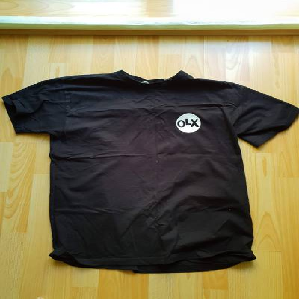

In [4]:
from tensorflow.keras.preprocessing.image import load_img


path = './clothing-dataset-small/train/t-shirt'
name = '5f0a3fa0-6a3d-4b68-b213-72766a643de7.jpg'
fullname = f'{path}/{name}'

img = load_img(fullname, target_size=(299, 299))
img

In [5]:
type(img)

PIL.Image.Image

### How an image is stored

A color image is 3 grids of numbers called **channels**: Red, Green and Blue.

- Shape is `(height, width, channels)`, e.g. `(150, 150, 3)`.
- Each pixel has 3 values `(R, G, B)`, one from each channel.
- Each value is 0–255 (1 byte). 0 means none of that color, and 255 means full. A black pixel is `(0, 0, 0)`.


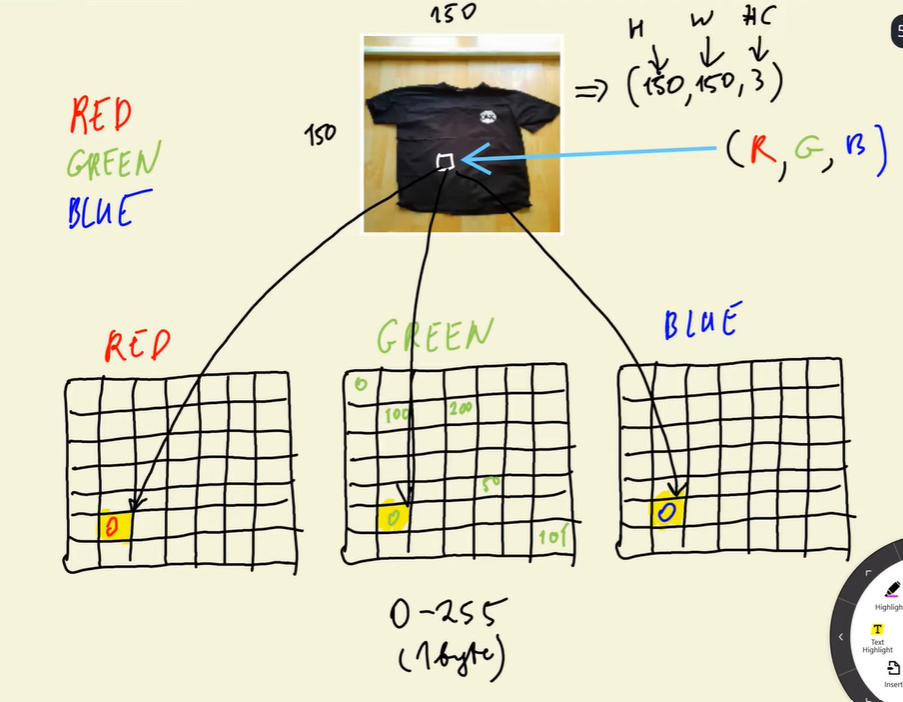

### Convert PIL image to NumPy array

In [6]:
img_array = np.array(img)
img_array

array([[[179, 171,  99],
        [179, 171,  99],
        [181, 173, 101],
        ...,
        [251, 253, 248],
        [251, 253, 248],
        [251, 254, 247]],

       [[188, 179, 112],
        [187, 178, 111],
        [186, 177, 108],
        ...,
        [251, 252, 247],
        [251, 252, 247],
        [251, 252, 246]],

       [[199, 189, 127],
        [200, 190, 128],
        [200, 191, 126],
        ...,
        [250, 251, 245],
        [250, 251, 245],
        [250, 251, 245]],

       ...,

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [183, 135,  25],
        [181, 133,  22],
        [183, 135,  24]],

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [182, 134,  23],
        [180, 132,  21],
        [182, 134,  23]],

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [181, 133,  22],
        [179, 131,  20],
        [182, 134,  23]]

In [5]:
img_array.shape

(299, 299, 3)